In [1]:
import sys
sys.path.insert(0, "..")

import time
import numpy as np
import pandas as pd
import torch
import mlflow
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

from ml.common import ROOT, CAP, SEED, load_fd, select_sensors, rmse, nasa_score
from ml.sequences import make_windows
from ml.training import train_gru, predict, scale_windows

mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
mlflow.set_experiment("rul-fd001")

WIN = 30
ART_DIR = ROOT / "ml" / "artifacts"
ART_DIR.mkdir(parents=True, exist_ok=True)

train, test, rul = load_fd("FD001")
keep = select_sensors(train)

# Raw (unscaled) windows: scaling happens inside each fold, using only that fold's training data
X_raw, _ = make_windows(train, keep, WIN)
y = train["RUL"].to_numpy(dtype=np.float32)
groups = train["unit"].to_numpy()

Xt_all, _ = make_windows(test, keep, WIN)
test_r = test.reset_index(drop=True)
last_idx = test_r.groupby("unit").tail(1).index.to_numpy()
X_test_raw = Xt_all[last_idx]
y_test = np.minimum(rul["RUL"].values, CAP).astype(np.float32)
last_units = test_r.loc[last_idx, "unit"].values

print(X_raw.shape, X_test_raw.shape)

(20631, 30, 14) (100, 30, 14)


In [2]:
def split_inner(rows, rng, frac=0.15):
    """Hold out ~15% of the engines in `rows` as a validation set for early stopping."""
    units = np.unique(groups[rows])
    val_units = rng.choice(units, size=max(1, int(len(units) * frac)), replace=False)
    is_val = np.isin(groups[rows], val_units)
    return rows[~is_val], rows[is_val]


def fit_one(train_rows, seed, cfg, on_epoch=None):
    rng = np.random.default_rng(seed)
    fit_rows, val_rows = split_inner(train_rows, rng)

    # Scaler uses only the engines the model is trained on
    sub = train.iloc[fit_rows][keep]
    mean = sub.mean().to_numpy(dtype=np.float32)
    std = sub.std().to_numpy(dtype=np.float32)

    model, best_epoch, best_val = train_gru(
        scale_windows(X_raw[fit_rows], mean, std), y[fit_rows],
        scale_windows(X_raw[val_rows], mean, std), y[val_rows],
        seed=seed, on_epoch=on_epoch, **cfg,
    )
    return model, mean, std, best_epoch, best_val

In [3]:
t0 = time.time()
tr_idx, ho_idx = next(iter(GroupKFold(n_splits=5).split(X_raw, y, groups)))
cfg_test = dict(hidden=64, lr=1e-3, batch=256, epochs=2, patience=6)
_, _, _, ep, val = fit_one(tr_idx, SEED, cfg_test)
print(f"2 epochs took {time.time() - t0:.0f}s | val RMSE after 2 epochs: {val:.1f}")

2 epochs took 99s | val RMSE after 2 epochs: 20.6


In [4]:
def run_gru(run_name, cfg):
    t0 = time.time()
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({"model": "gru", "dataset": "FD001"})
        mlflow.log_params({"window": WIN, "n_features": len(keep), "rul_cap": CAP,
                           "scaler": "refit per fold",
                           "early_stopping_val": "15% of training engines", **cfg})

        cv, best_eps = [], []
        for fold, (tr_idx, ho_idx) in enumerate(GroupKFold(n_splits=5).split(X_raw, y, groups), 1):
            model, mean, std, best_ep, _ = fit_one(tr_idx, SEED + fold, cfg)
            pred = predict(model, scale_windows(X_raw[ho_idx], mean, std))
            score = rmse(y[ho_idx], pred)
            cv.append(score); best_eps.append(best_ep)
            mlflow.log_metric("fold_rmse", score, step=fold)
            print(f"fold {fold}: RMSE {score:.2f} (best epoch {best_ep}, {time.time() - t0:.0f}s elapsed)")

        # Final model on all training engines; its validation curve is logged per epoch
        model, mean, std, best_ep, _ = fit_one(
            np.arange(len(y)), SEED, cfg,
            on_epoch=lambda e, v: mlflow.log_metric("final_val_rmse", v, step=e),
        )
        preds = predict(model, scale_windows(X_test_raw, mean, std))

        metrics = {
            "cv_rmse": float(np.mean(cv)),
            "cv_rmse_std": float(np.std(cv)),
            "test_rmse": rmse(y_test, preds),
            "test_nasa": nasa_score(y_test, preds),
            "final_best_epoch": float(best_ep),
        }
        mlflow.log_metrics(metrics)

        torch.save(model.state_dict(), ART_DIR / f"{run_name}.pt")
        np.savez(ART_DIR / f"{run_name}_scaler.npz", mean=mean, std=std)
        pd.DataFrame({"unit": last_units, "true_rul": y_test, "pred_rul": preds}).to_csv(
            ART_DIR / f"{run_name}_test_predictions.csv", index=False)
        for f in [f"{run_name}.pt", f"{run_name}_scaler.npz", f"{run_name}_test_predictions.csv"]:
            mlflow.log_artifact(str(ART_DIR / f))
    return metrics


cfg = dict(hidden=64, lr=1e-3, batch=256, epochs=40, patience=6)
print(run_gru("gru_win30_h64", cfg))

fold 1: RMSE 13.47 (best epoch 11, 469s elapsed)
fold 2: RMSE 12.38 (best epoch 12, 1137s elapsed)
fold 3: RMSE 13.27 (best epoch 20, 2382s elapsed)
fold 4: RMSE 12.11 (best epoch 23, 3431s elapsed)
fold 5: RMSE 13.56 (best epoch 11, 4230s elapsed)
{'cv_rmse': 12.955169677734375, 'cv_rmse_std': 0.5956567175854599, 'test_rmse': 14.033365249633789, 'test_nasa': 382.766845703125, 'final_best_epoch': 9.0}


In [5]:
runs = mlflow.search_runs(experiment_names=["rul-fd001"])
table = runs[["tags.mlflow.runName", "metrics.cv_rmse", "metrics.cv_rmse_std",
              "metrics.test_rmse", "metrics.test_nasa"]].copy()
table.columns = ["run", "cv_rmse", "cv_std", "test_rmse", "test_nasa"]
table.sort_values("cv_rmse").round(2)

,run,cv_rmse,cv_std,test_rmse,test_nasa
0,gru_win30_h64,12.96,0.60,14.03,382.77
1,xgb_win30_slope,13.20,0.56,13.11,257.08
2,xgb_win20_slope,15.52,0.60,15.57,443.20
3,xgb_win10_noslope,18.95,0.59,18.55,1357.13


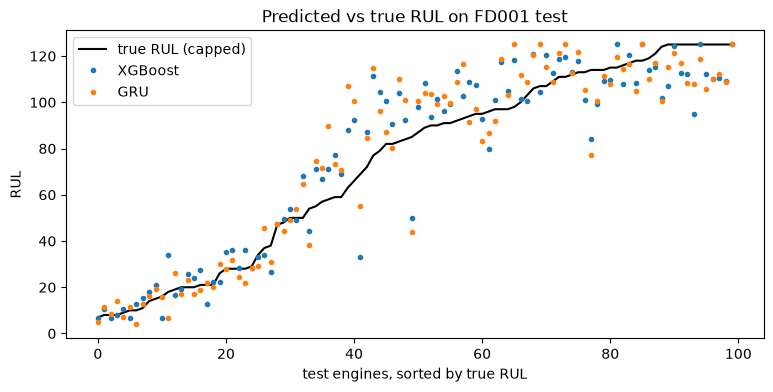

In [6]:
xgb = pd.read_csv(ART_DIR / "xgb_win30_slope_test_predictions.csv")
gru = pd.read_csv(ART_DIR / "gru_win30_h64_test_predictions.csv")
order = np.argsort(xgb["true_rul"].values)

plt.figure(figsize=(9, 4))
plt.plot(xgb["true_rul"].values[order], "k-", label="true RUL (capped)")
plt.plot(xgb["pred_rul"].values[order], ".", label="XGBoost")
plt.plot(gru["pred_rul"].values[order], ".", label="GRU")
plt.xlabel("test engines, sorted by true RUL")
plt.ylabel("RUL")
plt.legend()
plt.title("Predicted vs true RUL on FD001 test")
plt.show()

| Model | CV RMSE | CV std | Test RMSE | NASA score |
|---|---|---|---|---|
| XGBoost, window 30 + slope | 13.20 | 0.56 | 13.11 | (your value) |
| GRU, window 30, hidden 64 | (value) | (value) | (value) | (value) |